# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [12]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    select_existing_columns,
    summarize_pair_publication_rates,
)


## Configuration


In [14]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PARQUET_OUTPUT_DIR = OUTPUT_DIR / "parquets"
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = PARQUET_OUTPUT_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PARQUET_OUTPUT_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = PROJECT_ROOT / "assets" / "antibiotic_coarsening_lookup.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "Antibiotic" #Antibiotic,Class,Simplified categories,High level categories,Origin
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]

FIT_START_YEAR = 2000
FIT_END_YEAR = 2023
NUM_FUTURE_YEARS = 5

MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = 5.0
MIN_CURRENT_PREDICTED_COUNT = 10
MIN_FUTURE_PREDICTED_COUNT = 10
MIN_SI_CHANGE = 0.07
MIN_POST_FIT_OBSERVED_YEARS = 1
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 750.0
FALLBACK_TOP_N = 10

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_LOOKBACK_YEARS = 5
MAX_DRIVER_PLOTS = 25
MAX_INTERESTING_PLOTS = 25
FIGURE_FORMAT = "pdf"
DISPLAY_PLOTS = True
MAX_DISPLAY_PLOTS = 10
FILL_MISSING_AMR_COUNTS_WITH_ZERO = True
PLOT_END_YEAR = FIT_END_YEAR + NUM_FUTURE_YEARS


## Load Canonical Inputs


In [15]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 14,981
yearly_screened unique pathogens: 20
yearly_screened unique antibiotics: 197
yearly_screened year range: 2000 - 2026
pathogen bg rows: 540
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 105,331


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [16]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 14,981
model pathogen-antibiotic rows: 1,627
model antibiotic values: 197
model antibiotic background rows: 5,319
model unified decision rows: 105,331


,pathogen,antibiotic,year,pmids,count
0,Acinetobacter baumannii,Amikacin,2001,"[11192508, 11450883, 12593705]",3
1,Acinetobacter baumannii,Amikacin,2002,"[11864948, 12481673]",2
2,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14619453, 14748260]",3
3,Acinetobacter baumannii,Amikacin,2004,"[14964402, 15004037, 15164966, 15221039, 16163...",5
4,Acinetobacter baumannii,Amikacin,2005,"[15667800, 16103700, 16258323, 16308938]",4
5,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2
6,Acinetobacter baumannii,Amikacin,2007,"[17762241, 18167265]",2
7,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18624668, 18792817, 18974485, 19037...",6
8,Acinetobacter baumannii,Amikacin,2009,"[19795613, 19949755, 20583564]",3
9,Acinetobacter baumannii,Amikacin,2010,"[20028819, 20107089, 20186407, 20194701, 20499...",10


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [17]:
yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 187 / 1,627 pairs with >= 5 publications/year on average from 2000 to 2023.


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
1312,Staphylococcus aureus,Meticillin,4983,207.625000
308,Escherichia coli,Ampicillin,2142,89.250000
357,Escherichia coli,Ciprofloxacin,1832,76.333333
459,Escherichia coli,Tetracycline,1718,71.583333
1372,Staphylococcus aureus,Vancomycin,1692,70.500000
465,Escherichia coli,Trimethoprim,1490,62.083333
448,Escherichia coli,Sulfamethoxazole,1218,50.750000
449,Escherichia coli,Sulfamethoxazole/trimethoprim,1086,45.250000
571,Helicobacter pylori,Clarithromycin,1047,43.625000
388,Escherichia coli,Gentamicin,1031,42.958333


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [18]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_df.head(10)


SI rows: 4,853
SI pairs: 187


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Acinetobacter baumannii,Amikacin,2001,"[11192508, 11450883, 12593705]",3,60,167,0.602060,1.785330,2.225309,0.142532,0.388456,0.459528
1,Acinetobacter baumannii,Amikacin,2002,"[11864948, 12481673]",2,80,156,0.477121,1.908485,2.195900,0.218213,0.652771,0.258909
2,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14619453, 14748260]",3,80,183,0.602060,1.908485,2.264818,0.258178,0.812081,0.343882
3,Acinetobacter baumannii,Amikacin,2004,"[14964402, 15004037, 15164966, 15221039, 16163...",5,93,180,0.778151,1.973128,2.257679,0.302713,1.007767,0.475438
4,Acinetobacter baumannii,Amikacin,2005,"[15667800, 16103700, 16258323, 16308938]",4,139,187,0.698970,2.146128,2.274158,0.442537,1.770366,0.256433
5,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2,176,194,0.477121,2.247973,2.290035,0.528432,2.376234,-0.051311
6,Acinetobacter baumannii,Amikacin,2007,"[17762241, 18167265]",2,205,192,0.477121,2.313867,2.285557,0.575454,2.762303,-0.098332
7,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18624668, 18792817, 18974485, 19037...",6,247,228,0.845098,2.394452,2.359835,0.679206,3.777563,0.165892
8,Acinetobacter baumannii,Amikacin,2009,"[19795613, 19949755, 20583564]",3,287,256,0.602060,2.459392,2.409933,0.757158,4.716860,-0.155098
9,Acinetobacter baumannii,Amikacin,2010,"[20028819, 20107089, 20186407, 20194701, 20499...",10,342,265,1.041393,2.535294,2.424882,0.822979,5.652415,0.218413


## Rank Reliable Future High-Interest Pairs


In [19]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/187] ranking Acinetobacter baumannii vs Amikacin
[2/187] ranking Acinetobacter baumannii vs Ampicillin
[3/187] ranking Acinetobacter baumannii vs Ceftazidime
[4/187] ranking Acinetobacter baumannii vs Ceftolozane/tazobactam
[5/187] ranking Acinetobacter baumannii vs Ciprofloxacin
[6/187] ranking Acinetobacter baumannii vs Colistin
[7/187] ranking Acinetobacter baumannii vs Gentamicin
[8/187] ranking Acinetobacter baumannii vs Meropenem
[9/187] ranking Acinetobacter baumannii vs Meticillin
[10/187] ranking Acinetobacter baumannii vs Piperacillin
[11/187] ranking Acinetobacter baumannii vs Piperacillin/tazobactam
[12/187] ranking Acinetobacter baumannii vs Sulbactam
[13/187] ranking Acinetobacter baumannii vs Tazobactam
[14/187] ranking Acinetobacter baumannii vs Tetracycline
[15/187] ranking Acinetobacter baumannii vs Tigecycline
[16/187] ranking Acinetobacter baumannii vs Vancomycin
[17/187] ranking Clostridioides difficile vs Clindamycin
[18/187] ranking Clostridioides difficile vs

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Escherichia coli,Colistin,0.306430,0.438967,233.171395,892.012216,75.456349
1,Klebsiella pneumoniae,Ceftazidime/avibactam,0.208293,0.349563,38.177862,160.309880,32.028512
2,Escherichia coli,Meropenem,0.190141,0.282482,105.604209,308.747534,14.132338
3,Escherichia coli,Fosfomycin,0.145705,0.230584,56.652688,136.619997,9.986497
4,Staphylococcus aureus,Cefotaxime,0.145314,0.288884,23.206659,70.089897,187.524763
5,Escherichia coli,Cefotaxime,0.139625,0.206781,114.688935,241.599145,21.996213
6,Escherichia coli,Levofloxacin,0.137768,0.248764,38.703430,92.499112,137.739347
7,Escherichia coli,Vancomycin,0.133335,0.239989,27.438410,60.329357,78.473182
8,Klebsiella pneumoniae,Nitrofurantoin,0.124970,0.232140,24.268109,83.484503,102.721682
9,Escherichia coli,Cefuroxime,0.120971,0.214018,26.484767,54.544967,47.820160


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [20]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Escherichia coli,Colistin,0.306430,0.438967,233.171395,892.012216,564,403,RESISTANCE_PREVALENCE_SURVEILLANCE,ONE_HEALTH_ENVIRONMENTAL_RESERVOIR,0.007092,0.904255
1,Klebsiella pneumoniae,Ceftazidime/avibactam,0.208293,0.349563,38.177862,160.309880,110,107,RESISTANCE_MECHANISM,RESISTANCE_PREVALENCE_SURVEILLANCE,0.009091,0.881818
2,Escherichia coli,Meropenem,0.190141,0.282482,105.604209,308.747534,303,206,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_MECHANISM,0.003300,0.858086
3,Escherichia coli,Fosfomycin,0.145705,0.230584,56.652688,136.619997,169,110,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.739645
4,Staphylococcus aureus,Cefotaxime,0.145314,0.288884,23.206659,70.089897,65,46,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.876923
5,Escherichia coli,Cefotaxime,0.139625,0.206781,114.688935,241.599145,355,186,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.000000,0.859155
6,Escherichia coli,Levofloxacin,0.137768,0.248764,38.703430,92.499112,121,78,RESISTANCE_PREVALENCE_SURVEILLANCE,DIAGNOSTIC_STEWARDSHIP,0.000000,0.743802
7,Escherichia coli,Vancomycin,0.133335,0.239989,27.438410,60.329357,76,49,RESISTANCE_PREVALENCE_SURVEILLANCE,TREATMENT_EFFECTIVENESS,0.000000,0.868421
8,Klebsiella pneumoniae,Nitrofurantoin,0.124970,0.232140,24.268109,83.484503,82,67,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_MECHANISM,0.000000,0.890244
9,Escherichia coli,Cefuroxime,0.120971,0.214018,26.484767,54.544967,86,47,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_MECHANISM,0.000000,0.906977


## Plot Category Driver Curves


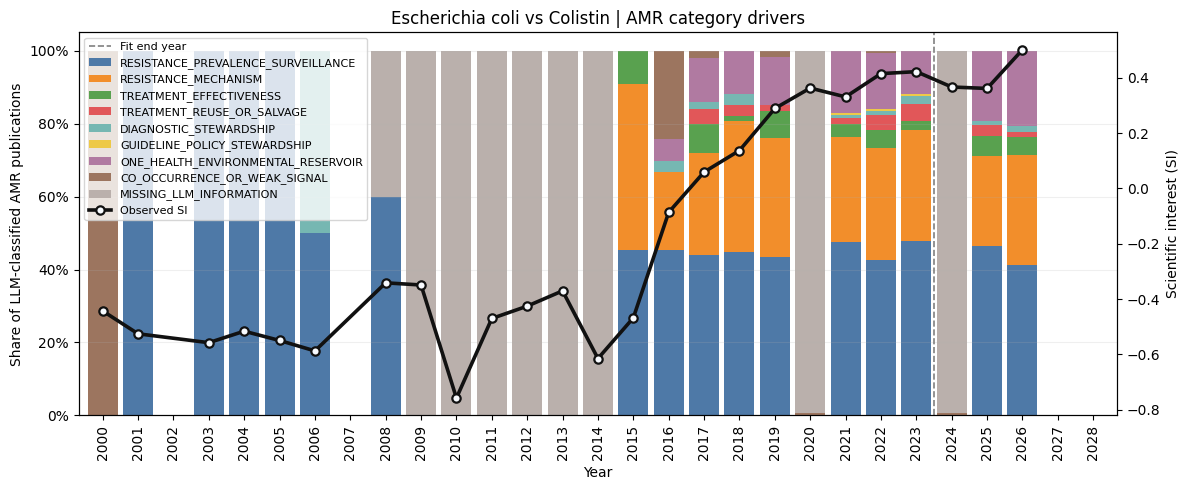

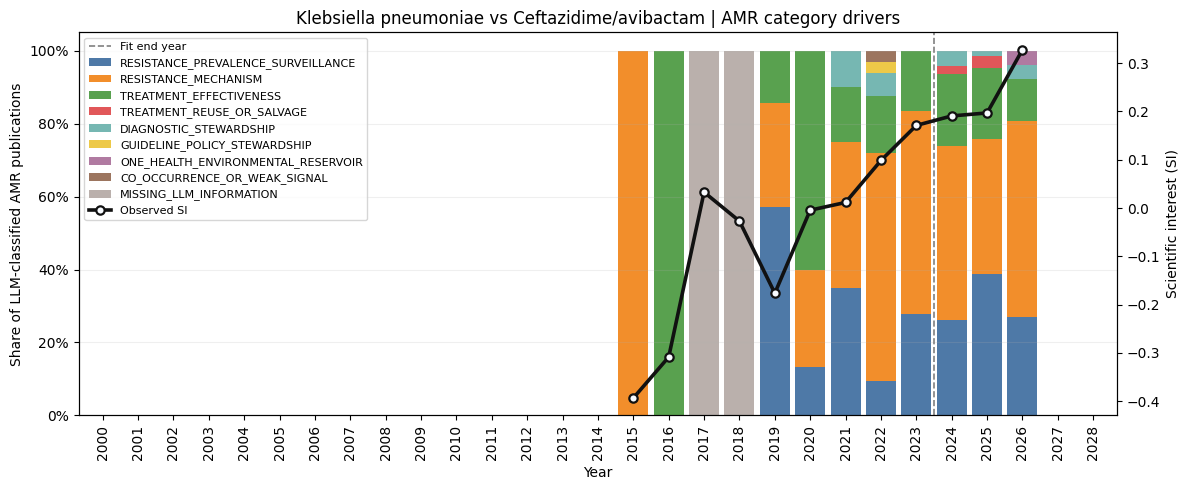

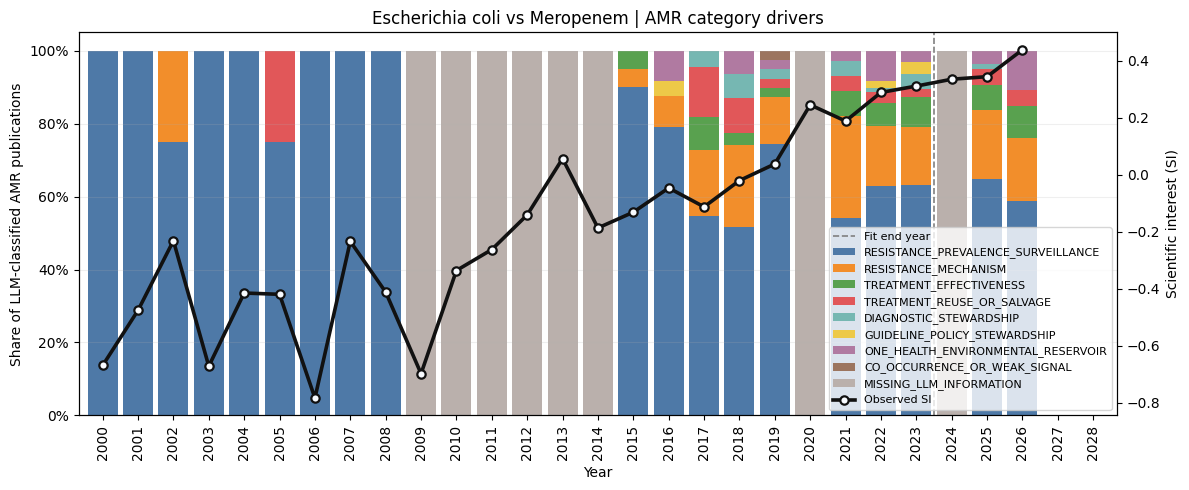

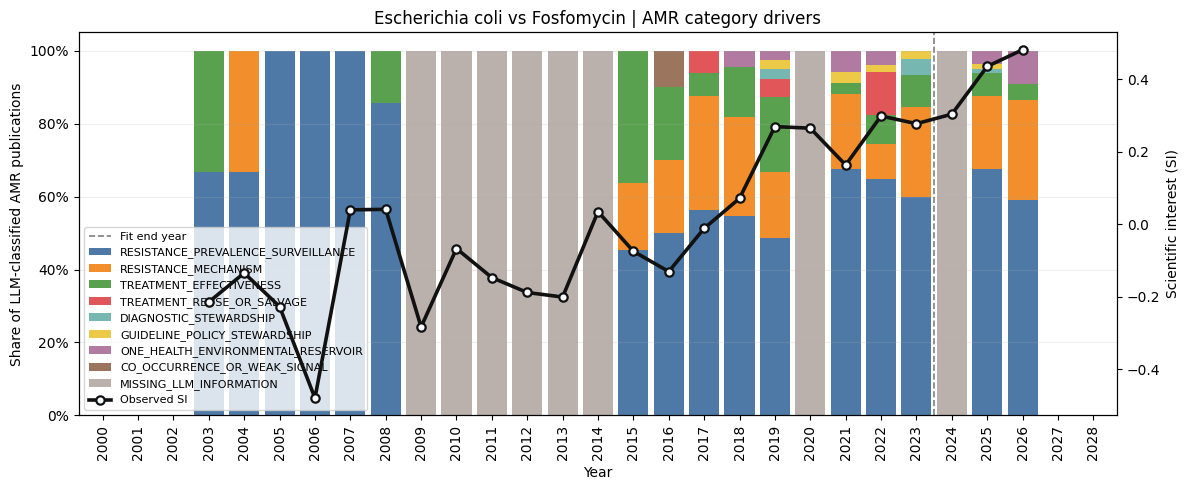

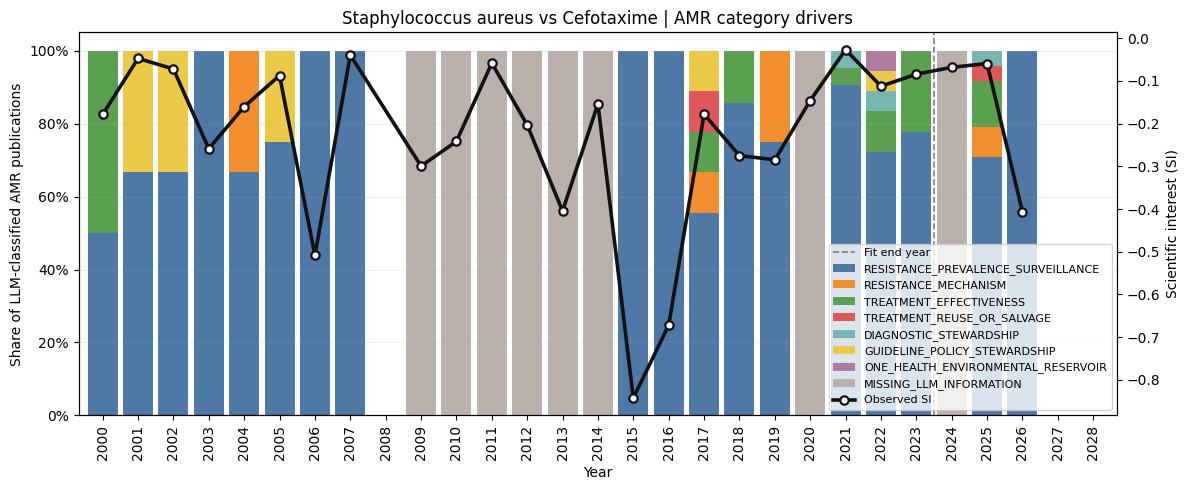

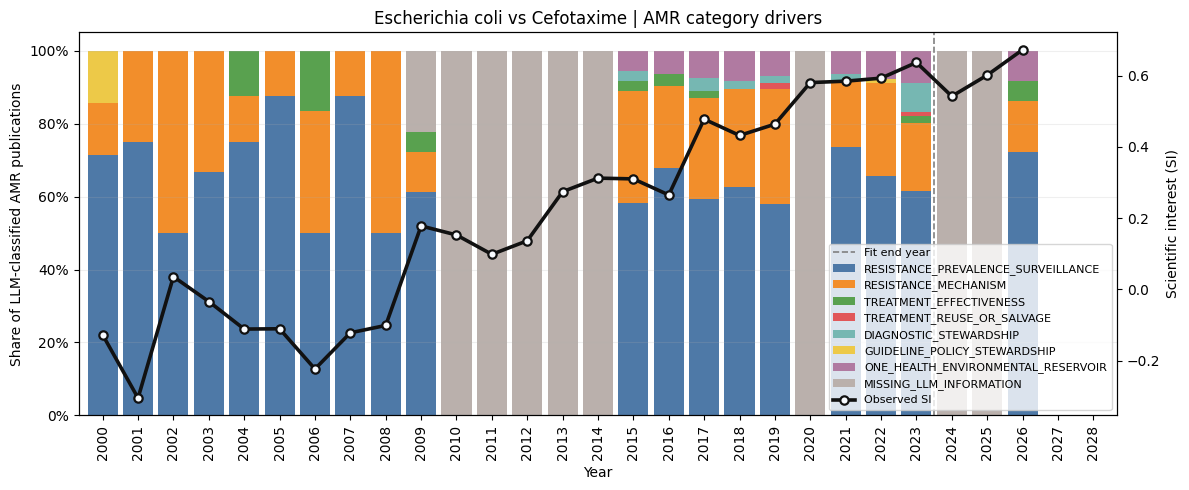

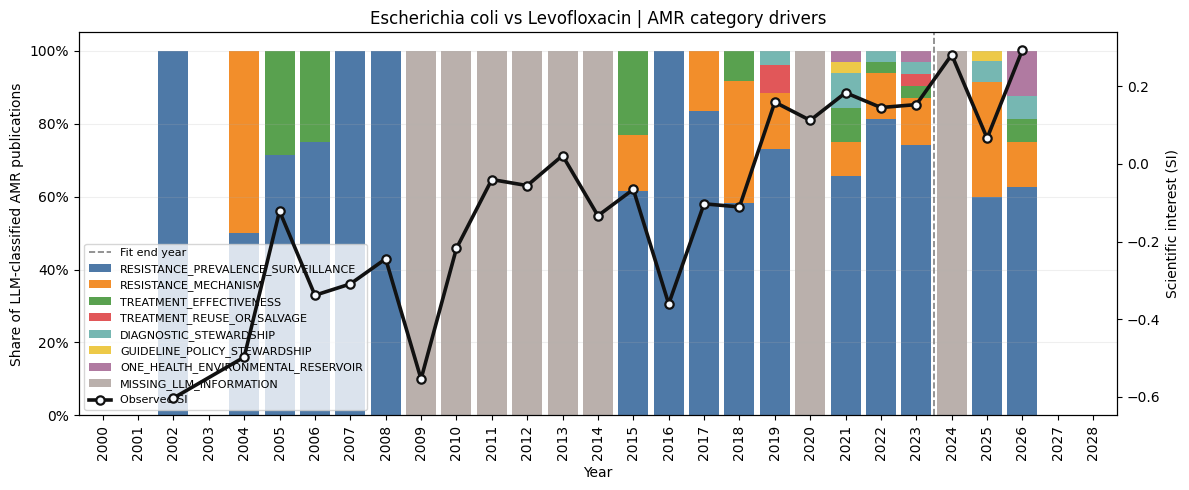

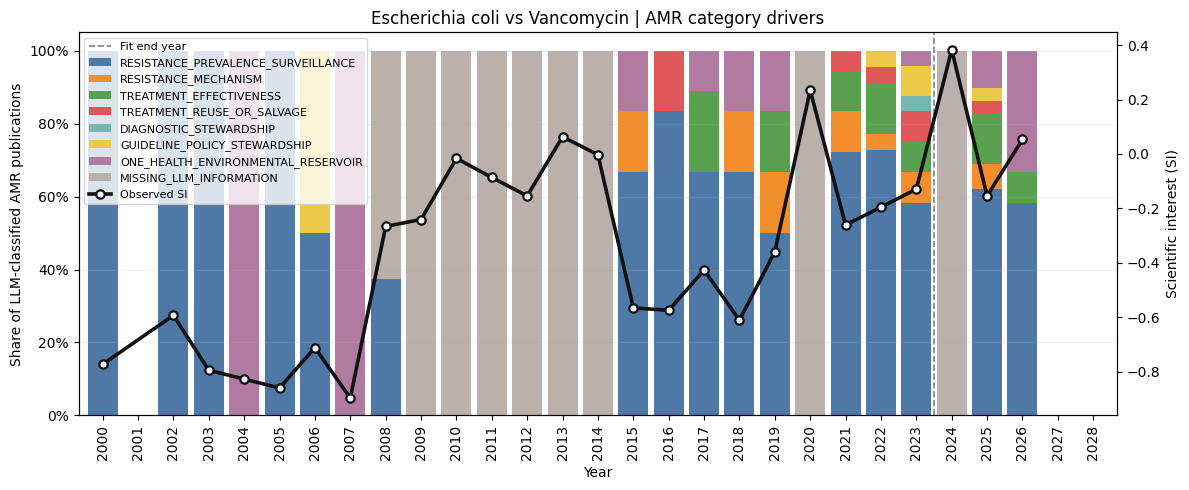

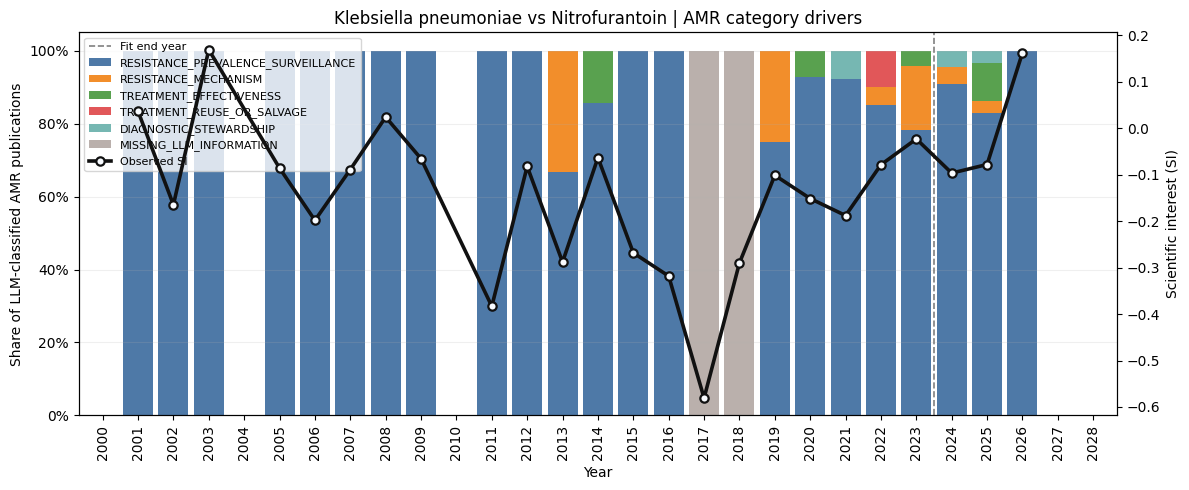

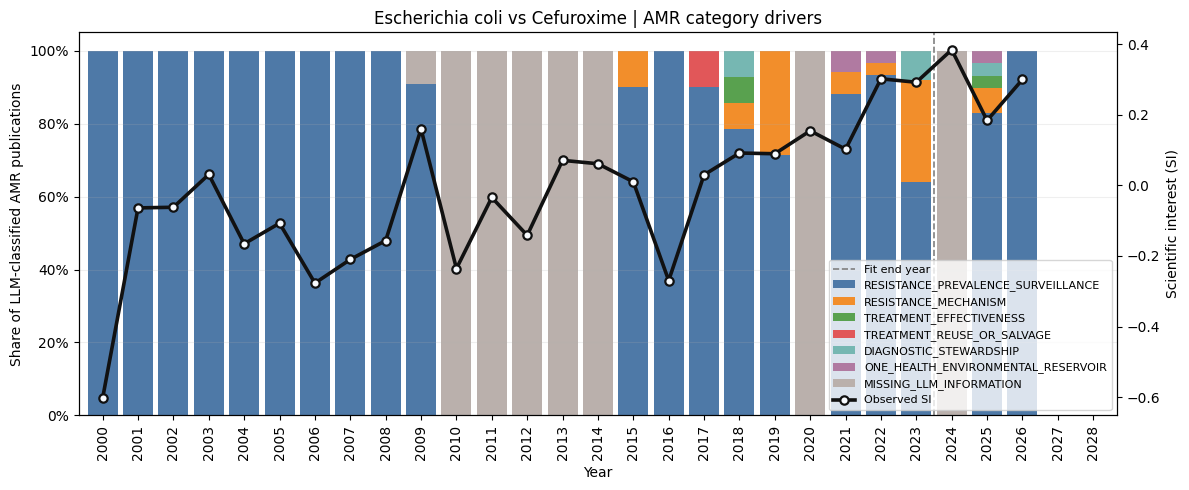

Saved 25 category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.


In [21]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


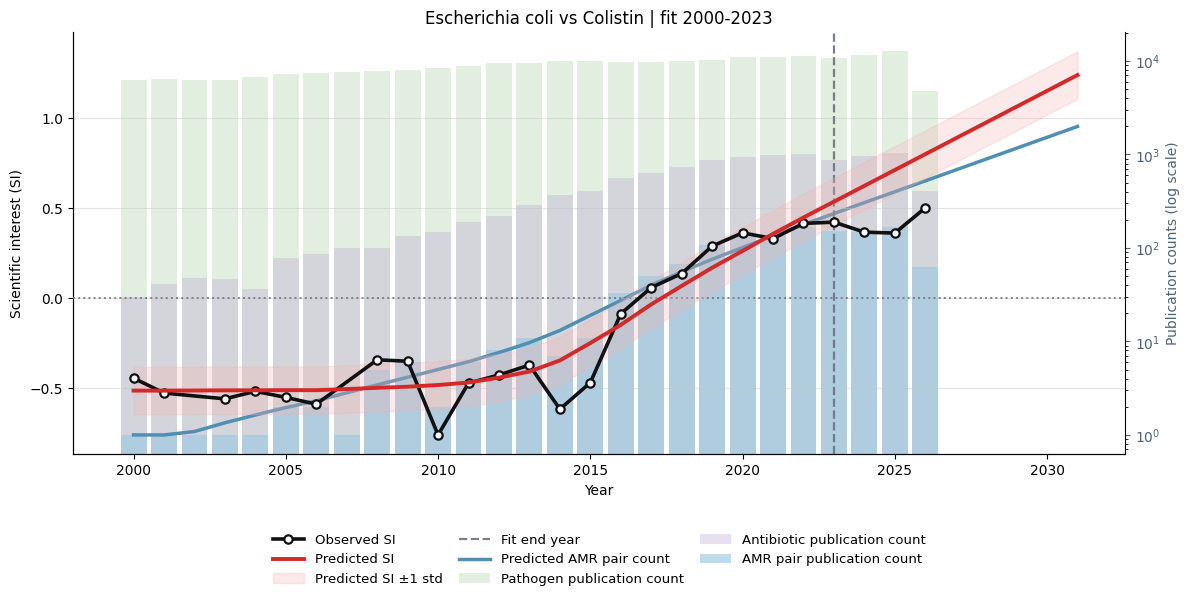

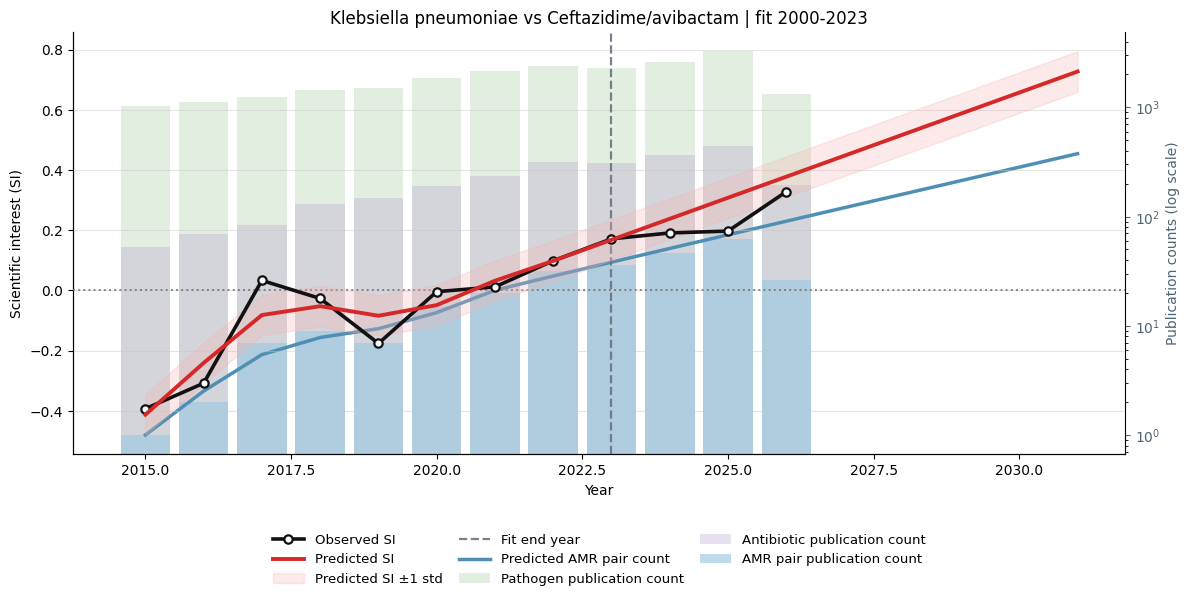

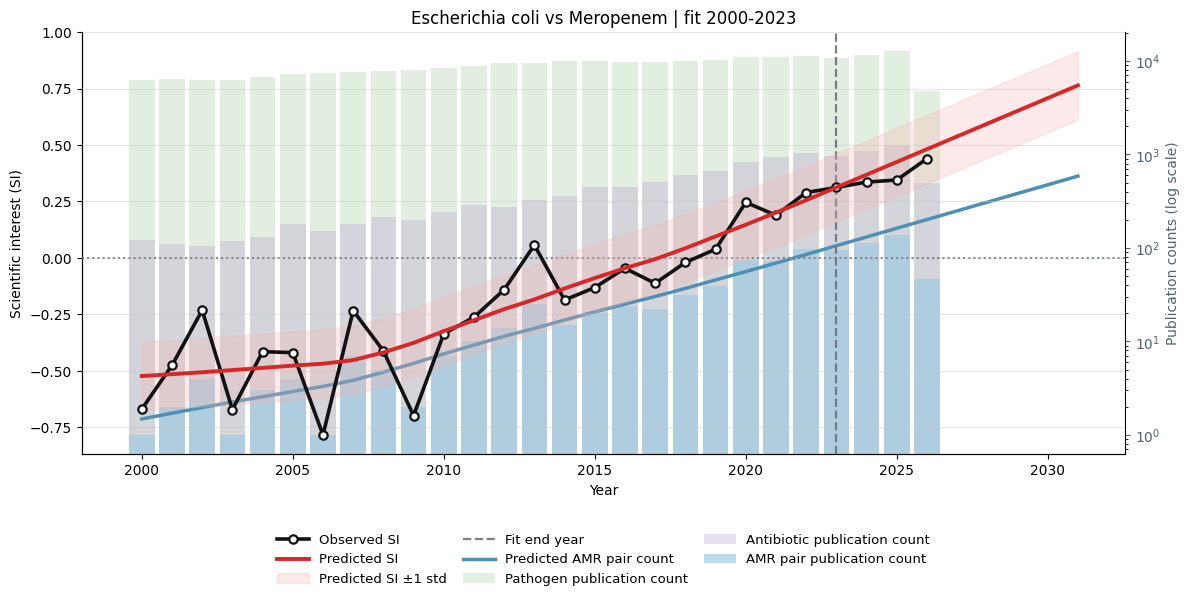

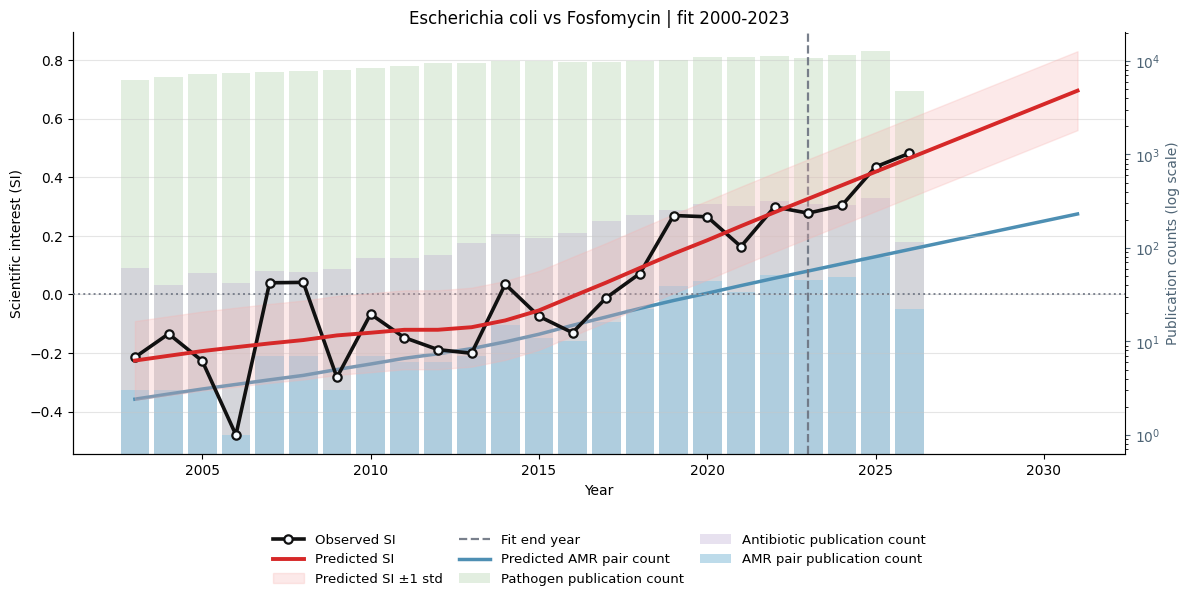

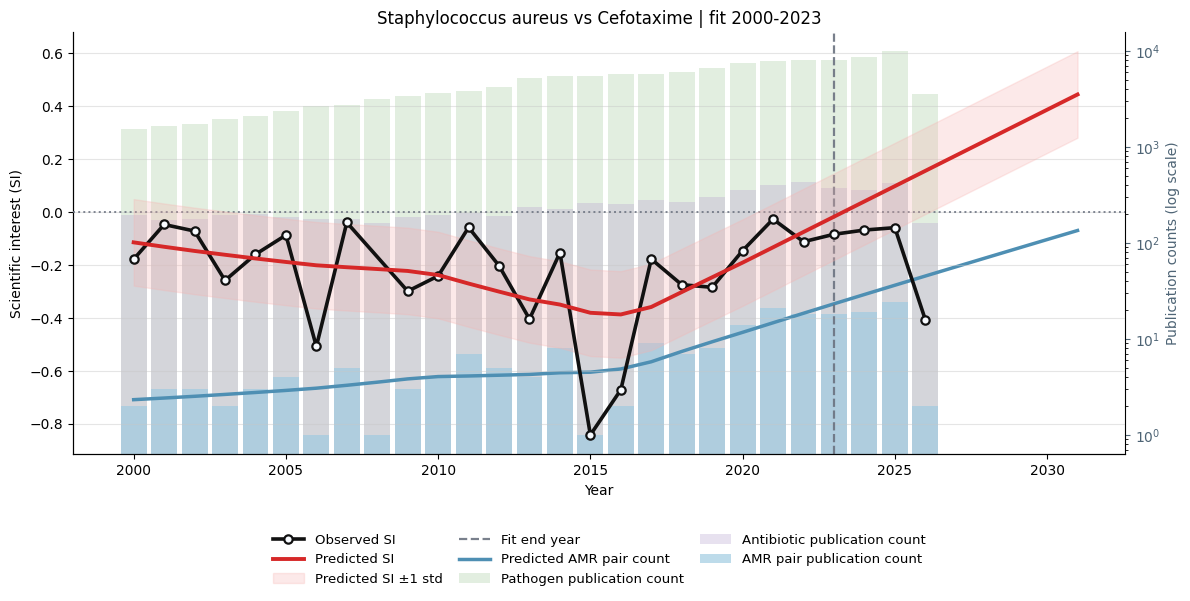

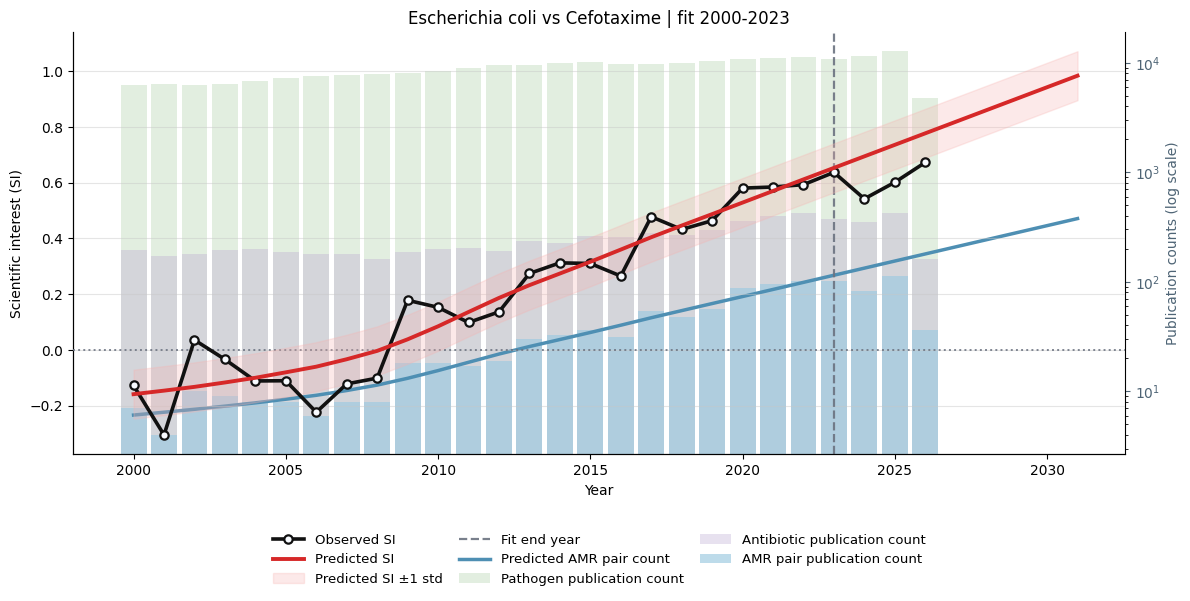

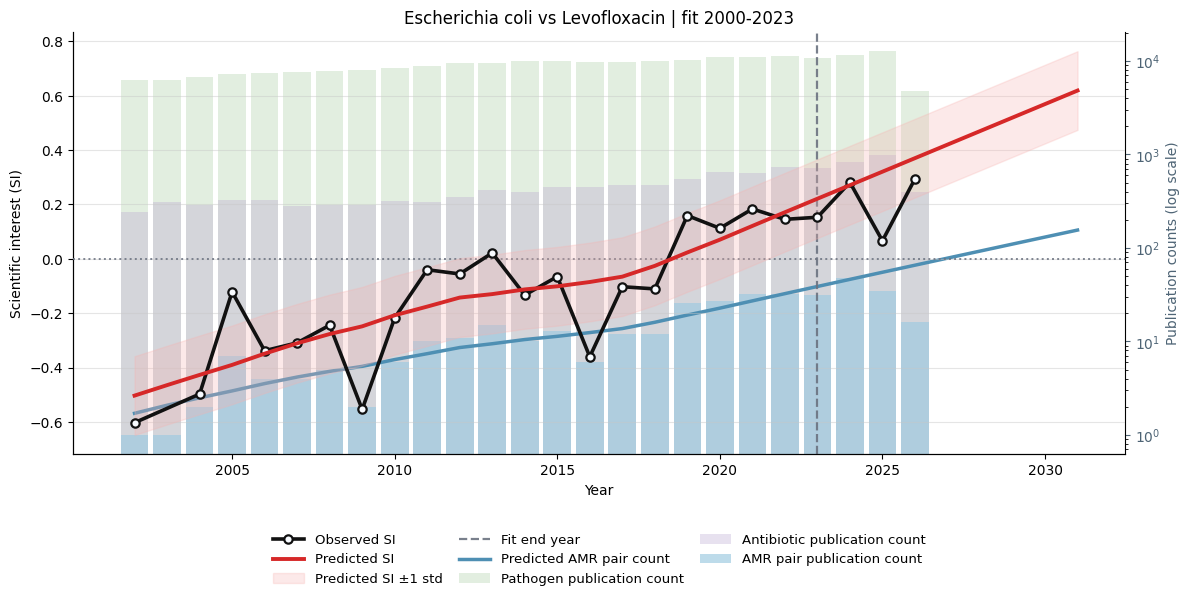

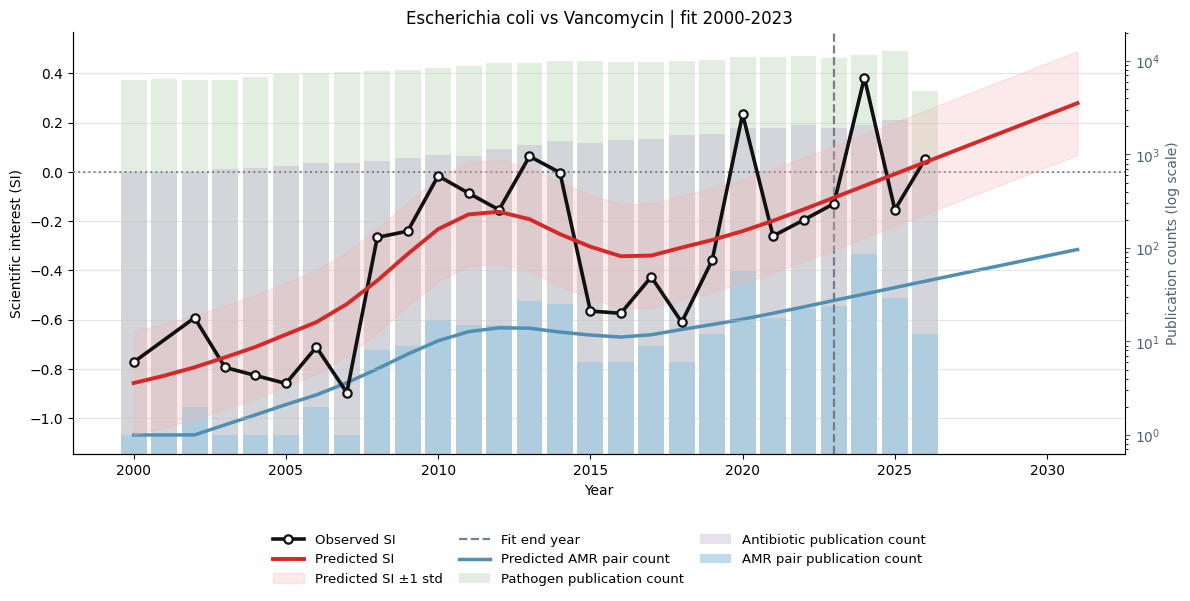

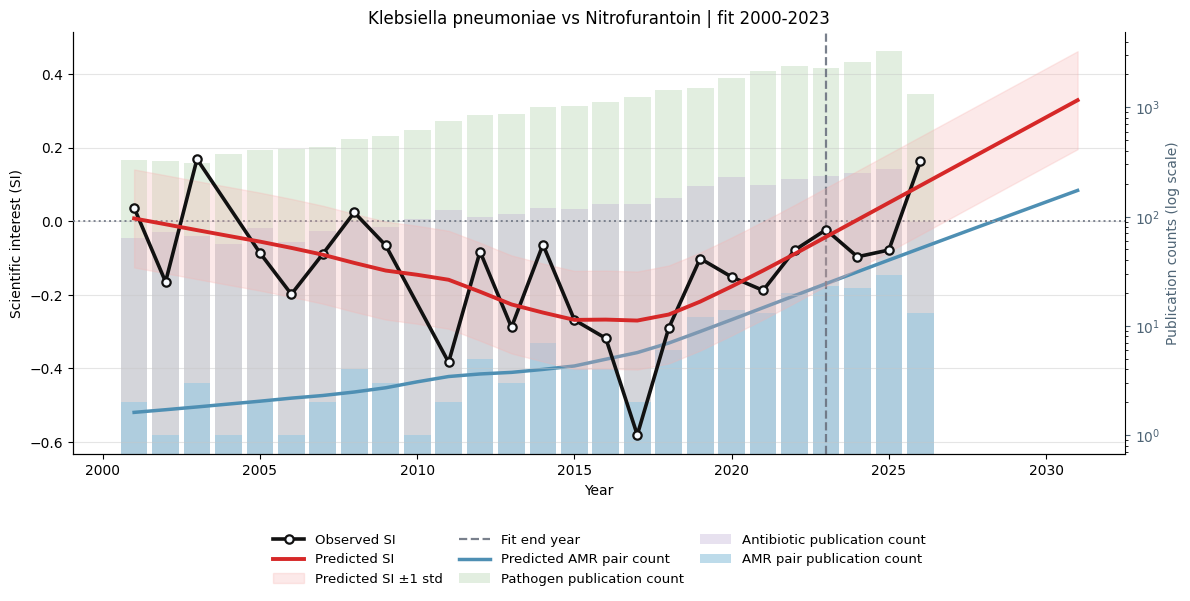

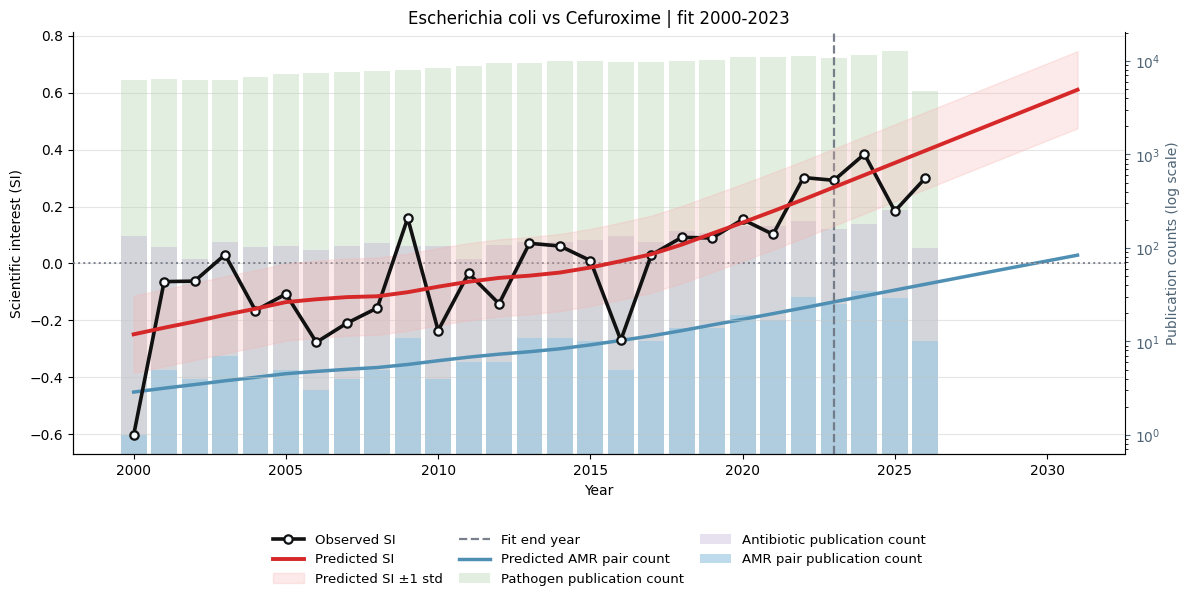

Saved 25 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [22]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)
